Célula 1: IMPORTS


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import unicodedata

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

import tensorflow as tf
from tensorflow.keras import layers, regularizers, callbacks

Célula 2: CARREGAR A BASE


In [2]:
caminho = "CelularesSubtraidos_2025.xlsx"
df = pd.read_excel(caminho, sheet_name='CELULAR_2025')

print(f"✅ Base carregada. Linhas originais: {len(df)}")
print("Colunas disponíveis:", df.columns.tolist())

✅ Base carregada. Linhas originais: 383635
Colunas disponíveis: ['ID_DELEGACIA', 'NOME_DEPARTAMENTO', 'NOME_SECCIONAL', 'NOME_DELEGACIA', 'NOME_MUNICIPIO', 'ANO_BO', 'NUM_BO', 'VERSAO', 'NOME_DEPARTAMENTO_CIRC', 'NOME_SECCIONAL_CIRC', 'NOME_DELEGACIA_CIRC', 'NOME_MUNICIPIO_CIRC', 'DATA_OCORRENCIA_BO', 'HORA_OCORRENCIA', 'DESCRICAO_APRESENTACAO', 'DATAHORA_REGISTRO_BO', 'DATA_COMUNICACAO_BO', 'DATAHORA_IMPRESSAO_BO', 'DESCR_PERIODO', 'AUTORIA_BO', 'FLAG_INTOLERANCIA', 'TIPO_INTOLERANCIA', 'FLAG_FLAGRANTE', 'FLAG_STATUS', 'DESC_LEI', 'FLAG_ATO_INFRACIONAL', 'RUBRICA', 'DESCR_CONDUTA', 'DESDOBRAMENTO', 'CIRCUNSTANCIA', 'DESCR_TIPOLOCAL', 'DESCR_SUBTIPOLOCAL', 'CIDADE', 'BAIRRO', 'CEP', 'LOGRADOURO_VERSAO', 'LOGRADOURO', 'NUMERO_LOGRADOURO', 'LATITUDE', 'LONGITUDE', 'CONT_OBJETO', 'DESCR_MODO_OBJETO', 'DESCR_TIPO_OBJETO', 'DESCR_SUBTIPO_OBJETO', 'DESCR_UNIDADE', 'QUANTIDADE_OBJETO', 'MARCA_OBJETO', 'FLAG_BLOQUEIO', 'FLAG_DESBLOQUEIO', 'MES_REGISTRO_BO', 'ANO_REGISTRO_BO', 'CMD', 'BTL', 'CI

Célula 3: recorte, rótulo e deduplicação


In [3]:
# Recorte geográfico (município do FATO = S.PAULO)
df = df[df['NOME_MUNICIPIO_CIRC'] == 'S.PAULO'].copy()
print(f"Após filtro S.PAULO: {len(df)}")

# Rótulo (apenas roubo e furto)
print("\nRubricas encontradas:")
print(df['RUBRICA'].value_counts().head(10))

filtro_roubo = df['RUBRICA'].str.contains(r'Roubo \(art\. 157\)', regex=True, na=False)
filtro_furto = df['RUBRICA'].str.contains(r'Furto \(art\. 155\)', regex=True, na=False)
df = df[filtro_roubo | filtro_furto].copy()
df['target'] = df['RUBRICA'].apply(lambda x: 1 if 'Roubo' in x else 0)
print(f"Após filtro Roubo/Furto: {len(df)}")

# Deduplicação (B.O.s repetidos)
dups = df.duplicated(subset=['NOME_DELEGACIA', 'ANO_BO', 'NUM_BO']).sum()
print(f"Duplicatas encontradas: {dups}")
df = df.drop_duplicates(subset=['NOME_DELEGACIA', 'ANO_BO', 'NUM_BO']).copy()
print(f"Após deduplicação: {len(df)}")

Após filtro S.PAULO: 216287

Rubricas encontradas:
RUBRICA
Furto (art. 155)                              106449
Roubo (art. 157)                               77488
Perda/Extravio                                 22133
Localização/Apreensão e Entrega de veículo      2600
Estelionato (art. 171)                          1055
Outros não criminal                              812
Localização/Apreensão de veículo                 621
Extorsão (art. 158)                              581
Lesão corporal (art. 129)                        455
Localização/Apreensão e Entrega de objeto        442
Name: count, dtype: int64
Após filtro Roubo/Furto: 183937
Duplicatas encontradas: 22224
Após deduplicação: 161713


Tratamento de Textos (Abreviações e Acentos) + Tratamento de Hora


In [4]:
# Funções de Limpeza 
def limpar_texto(texto):
    if pd.isna(texto): return texto
    texto = str(texto).upper().strip()
    return ''.join(c for c in unicodedata.normalize('NFD', texto) if unicodedata.category(c) != 'Mn')

def padronizar_bairro(bairro):
    if pd.isna(bairro): return bairro
    b = str(bairro).upper().strip()
    b = b.replace('JD ', 'JARDIM ').replace('JD. ', 'JARDIM ')
    b = b.replace('VL ', 'VILA ').replace('VL. ', 'VILA ')
    b = b.replace('PQ ', 'PARQUE ').replace('PQ. ', 'PARQUE ')
    return b

# Aplicando a Limpeza nos Textos 
df['BAIRRO'] = df['BAIRRO'].apply(limpar_texto).apply(padronizar_bairro)
df['DESCR_TIPOLOCAL'] = df['DESCR_TIPOLOCAL'].apply(limpar_texto)
df['DESCR_PERIODO'] = df['DESCR_PERIODO'].apply(limpar_texto)
df['AUTORIA_BO'] = df['AUTORIA_BO'].apply(limpar_texto)
print("✅ Textos padronizados (Acentos removidos e Abreviações corrigidas).")

✅ Textos padronizados (Acentos removidos e Abreviações corrigidas).


Célula 4: variável numérica (hora) e tipos de variáveis


In [5]:
cols_hora = [c for c in df.columns if 'HORA' in c.upper()]
print("Colunas com 'HORA':", cols_hora)

if cols_hora:
    df['HORA'] = df[cols_hora[0]].astype(str).str.extract(r'^(\d{1,2})')[0].astype(float)
    df.loc[~df['HORA'].between(0, 23), 'HORA'] = np.nan
    hora_limpa = df['HORA'].fillna(12) # Preenche nulos com meio-dia
    df['HORA_SIN'] = np.sin(2 * np.pi * hora_limpa / 24)
    df['HORA_COS'] = np.cos(2 * np.pi * hora_limpa / 24)
    num_cols = ['HORA_SIN', 'HORA_COS'] # Agora temos 2 colunas numéricas
else:
    print("⚠️ Sem coluna de hora. Usando MES a partir da data.")
    cols_data = [c for c in df.columns if 'DATA' in c.upper()]
    print("Colunas com 'DATA':", cols_data)
    df['MES'] = pd.to_datetime(df[cols_data[0]], errors='coerce', dayfirst=True).dt.month
    num_cols = ['MES']

cat_cols = ['BAIRRO', 'DESCR_PERIODO', 'DESCR_TIPOLOCAL', 'AUTORIA_BO']

print("\n--- Tipos ---")
display(df[cat_cols + num_cols + ['target']].dtypes)
print("Numéricas:", num_cols)
print("Categóricas:", cat_cols)

Colunas com 'HORA': ['HORA_OCORRENCIA', 'DATAHORA_REGISTRO_BO', 'DATAHORA_IMPRESSAO_BO']

--- Tipos ---


BAIRRO                 str
DESCR_PERIODO          str
DESCR_TIPOLOCAL        str
AUTORIA_BO             str
HORA_SIN           float64
HORA_COS           float64
target               int64
dtype: object

Numéricas: ['HORA_SIN', 'HORA_COS']
Categóricas: ['BAIRRO', 'DESCR_PERIODO', 'DESCR_TIPOLOCAL', 'AUTORIA_BO']


Célula 5: ausentes, resumo e categorias “unknown”


In [6]:
print("--- Ausentes (%) antes do tratamento ---")
display((df[cat_cols + num_cols].isnull().mean() * 100).round(2))
display(df[num_cols].describe())

# Tratamento do período (nulos e padronização)
df['DESCR_PERIODO'] = df['DESCR_PERIODO'].fillna('Nao Informado').replace({
    'A noite': 'Noite', 'A tarde': 'Tarde', 'Pela manhã': 'Manha',
    'De madrugada': 'Madrugada', 'Em hora incerta': 'Hora Incerta'
})

# Procurar categorias "unknown"
palavras = ['desconhec', 'informad', 'incerta', 'ignorad', 'nao', 'não']
for c in cat_cols:
    vc = df[c].astype(str).value_counts()
    unk = vc[vc.index.str.lower().str.contains('|'.join(palavras))]
    print(f"\n{c} -> categorias suspeitas:")
    print(unk if len(unk) else "nenhuma")

--- Ausentes (%) antes do tratamento ---


BAIRRO              0.25
DESCR_PERIODO      48.80
DESCR_TIPOLOCAL     0.00
AUTORIA_BO          0.00
HORA_SIN            0.00
HORA_COS            0.00
dtype: float64

,HORA_SIN,HORA_COS
count,1.617130e+05,1.617130e+05
mean,-1.051109e-01,-4.873556e-01
std,5.072859e-01,7.029238e-01
min,-1.000000e+00,-1.000000e+00
25%,-5.000000e-01,-1.000000e+00
50%,1.224647e-16,-1.000000e+00
75%,1.224647e-16,6.123234e-17
max,1.000000e+00,1.000000e+00



BAIRRO -> categorias suspeitas:
nenhuma

DESCR_PERIODO -> categorias suspeitas:
DESCR_PERIODO
Nao Informado      78912
EM HORA INCERTA      511
Name: count, dtype: int64

DESCR_TIPOLOCAL -> categorias suspeitas:
DESCR_TIPOLOCAL
AREA NAO OCUPADA    111
Name: count, dtype: int64

AUTORIA_BO -> categorias suspeitas:
nenhuma


Célula 6: distribuição da classe alvo


              qtd  proporcao
target                      
Furto (0)  102005      0.631
Roubo (1)   59708      0.369


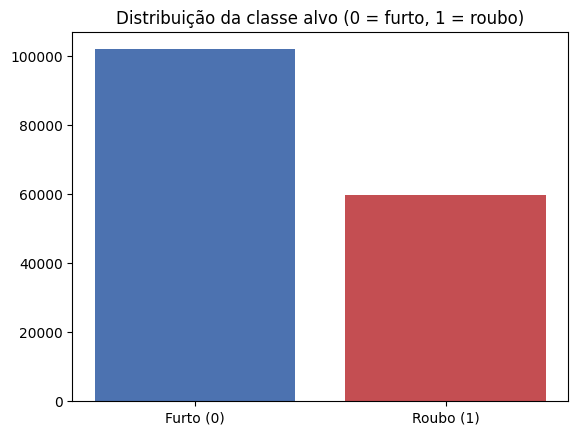

Classe minoritária: Roubo (36.9%)
Alvo em 0/1 → compatível com sigmoid + binary_crossentropy.


In [7]:
cont = df['target'].value_counts().sort_index()
prop = df['target'].value_counts(normalize=True).sort_index().round(3)
print(pd.DataFrame({'qtd': cont, 'proporcao': prop}).rename(index={0: 'Furto (0)', 1: 'Roubo (1)'}))

plt.bar(['Furto (0)', 'Roubo (1)'], cont.values, color=['#4c72b0', '#c44e52'])
plt.title('Distribuição da classe alvo (0 = furto, 1 = roubo)')
plt.show()

minoritaria = cont.idxmin()
print(f"Classe minoritária: {'Roubo' if minoritaria == 1 else 'Furto'} ({prop[minoritaria]:.1%})")
print("Alvo em 0/1 → compatível com sigmoid + binary_crossentropy.")

Célula 7: exploração numérica e categórica


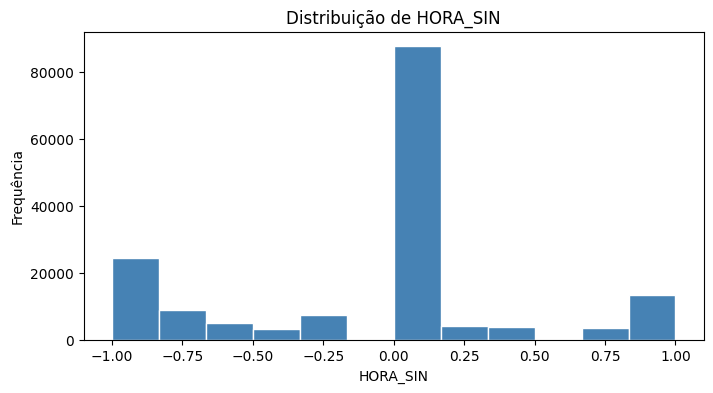

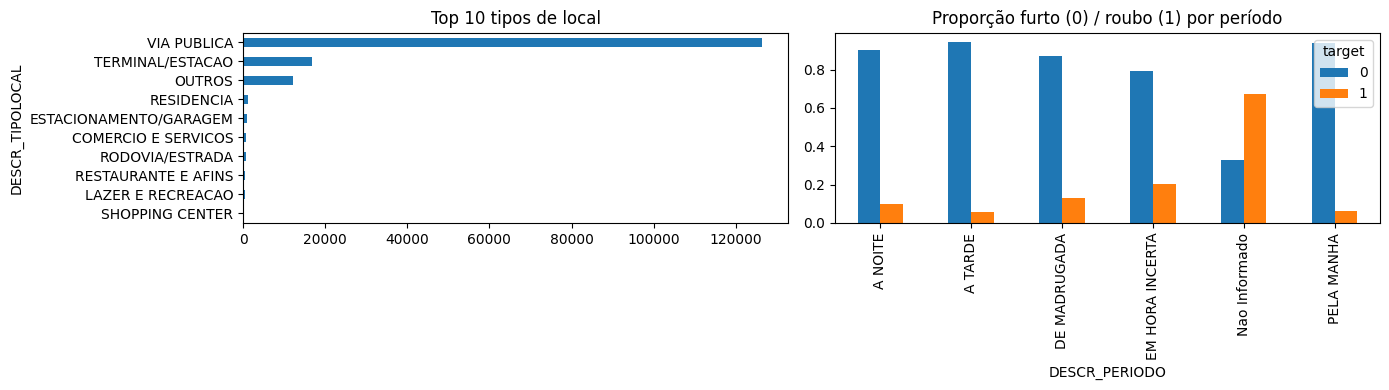

In [8]:
# Histograma da variável numérica
col_num = num_cols[0]
plt.figure(figsize=(8, 4))
plt.hist(df[col_num].dropna(), bins=24 if col_num == 'HORA' else 12, color='steelblue', edgecolor='white')
plt.xlabel(col_num); plt.ylabel('Frequência'); plt.title(f'Distribuição de {col_num}')
plt.show()

# Barras da variável categórica
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
df['DESCR_TIPOLOCAL'].value_counts().head(10).plot(kind='barh', ax=ax[0]); ax[0].invert_yaxis()
ax[0].set_title('Top 10 tipos de local')
pd.crosstab(df['DESCR_PERIODO'], df['target'], normalize='index').plot(kind='bar', ax=ax[1])
ax[1].set_title('Proporção furto (0) / roubo (1) por período')
plt.tight_layout(); plt.show()

Célula 8: verificação explícita de leakage


In [9]:
leakage = ['RUBRICA', 'target', 'NUM_BO', 'NOME_DELEGACIA', 'ANO_BO']
features_base = cat_cols + num_cols
assert not set(leakage) & set(features_base), "Leakage detectado nas features!"
print("Features usadas:", features_base)
print("Excluídas por leakage/identificação:", leakage)

Features usadas: ['BAIRRO', 'DESCR_PERIODO', 'DESCR_TIPOLOCAL', 'AUTORIA_BO', 'HORA_SIN', 'HORA_COS']
Excluídas por leakage/identificação: ['RUBRICA', 'target', 'NUM_BO', 'NOME_DELEGACIA', 'ANO_BO']


Célula 9: amostragem, divisão 70/15/15, salvar e carregar os 3 arquivos


In [10]:
# Amostragem estratificada + divisão
df_modelo = df[cat_cols + num_cols + ['target']].copy()   # RUBRICA, NUM_BO etc. ficam fora

if len(df_modelo) > 20000:
    df_modelo, _ = train_test_split(df_modelo, train_size=20000,
                                    stratify=df_modelo['target'], random_state=42)

train_df, tmp_df = train_test_split(df_modelo, test_size=0.30, stratify=df_modelo['target'], random_state=42)
val_df, test_df = train_test_split(tmp_df, test_size=0.50, stratify=tmp_df['target'], random_state=42)

train_df.to_csv('train.csv', index=False)
val_df.to_csv('validation.csv', index=False)
test_df.to_csv('test.csv', index=False)

# Carregar os três arquivos
train = pd.read_csv('train.csv')
val = pd.read_csv('validation.csv')
test = pd.read_csv('test.csv')
print(f"Treino: {train.shape} | Validação: {val.shape} | Teste: {test.shape}")

# Agrupamento de bairros (top 30 calculado SÓ no treino)
top_bairros = train['BAIRRO'].fillna('DESCONHECIDO').value_counts().nlargest(30).index.tolist()

def tratar(d):
    d = d.copy()
    d['BAIRRO'] = d['BAIRRO'].fillna('DESCONHECIDO')
    d['BAIRRO'] = d['BAIRRO'].where(d['BAIRRO'].isin(top_bairros), 'OUTROS_BAIRROS')
    for c in ['DESCR_PERIODO', 'DESCR_TIPOLOCAL', 'AUTORIA_BO']:
        d[c] = d[c].fillna('Desconhecido')
    return d

train, val, test = tratar(train), tratar(val), tratar(test)

# Separar entrada (X) e alvo (y)
features = cat_cols + num_cols
X_tr, y_tr = train[features], train['target'].values
X_val, y_val = val[features], val['target'].values
X_te, y_te = test[features], test['target'].values
print("X_tr:", X_tr.shape, "| y_tr:", y_tr.shape, "| Classes:", sorted(np.unique(y_tr)))

Treino: (14000, 7) | Validação: (3000, 7) | Teste: (3000, 7)
X_tr: (14000, 6) | y_tr: (14000,) | Classes: [np.int64(0), np.int64(1)]


Célula 10: tipos de variáveis e pré-processamento


In [11]:
# Identificar tipos
print("Tipos das features:")
display(X_tr.dtypes)
cat_cols_model = X_tr.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols_model = X_tr.select_dtypes(include=['number']).columns.tolist()
print("Categóricas:", cat_cols_model)
print("Numéricas:", num_cols_model)

# Pré-processamento (One-Hot + Scaling), ajustado SÓ no treino
preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols_model),
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                      ('scaler', StandardScaler())]), num_cols_model),
])

# Escalonamento (Fit apenas no treino)
X_tr_scaled = preprocessor.fit_transform(X_tr).astype('float32')
X_val_scaled = preprocessor.transform(X_val).astype('float32')
X_te_scaled = preprocessor.transform(X_te).astype('float32')
feature_names = preprocessor.get_feature_names_out()
print(f"\n✅ Dados prontos! Treino: {X_tr_scaled.shape} | Validação: {X_val_scaled.shape} | Teste: {X_te_scaled.shape}")

# Artefatos para o Streamlit
joblib.dump(preprocessor, 'preprocessor.pkl')
joblib.dump(top_bairros, 'top_bairros.pkl')
joblib.dump(list(feature_names), 'columns.pkl')

Tipos das features:


BAIRRO                 str
DESCR_PERIODO          str
DESCR_TIPOLOCAL        str
AUTORIA_BO             str
HORA_SIN           float64
HORA_COS           float64
dtype: object

Categóricas: ['BAIRRO', 'DESCR_PERIODO', 'DESCR_TIPOLOCAL', 'AUTORIA_BO']
Numéricas: ['HORA_SIN', 'HORA_COS']

✅ Dados prontos! Treino: (14000, 69) | Validação: (3000, 69) | Teste: (3000, 69)


C:\Users\ander\AppData\Local\Temp\ipykernel_17836\2534838626.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols_model = X_tr.select_dtypes(include=['object', 'category']).columns.tolist()


['columns.pkl']

Célula 11: Perceptron (manual e scikit-learn) e pesos


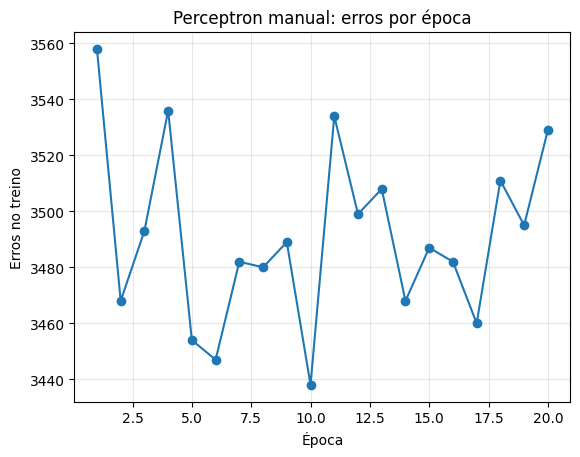

Bias (intercepto): -5.0000

Top 10 pesos que empurram para FURTO (negativos):
cat__BAIRRO_BOM RETIRO                              -5.0
cat__BAIRRO_LIBERDADE                               -5.0
cat__BAIRRO_PINHEIROS                               -5.0
cat__DESCR_TIPOLOCAL_LAZER E RECREACAO              -4.0
cat__DESCR_TIPOLOCAL_INTERNET                       -4.0
cat__DESCR_TIPOLOCAL_ESTABELECIMENTO DE ENSINO      -4.0
cat__DESCR_TIPOLOCAL_ENTIDADE ASSISTENCIAL          -4.0
cat__DESCR_PERIODO_PELA MANHA                       -4.0
cat__DESCR_TIPOLOCAL_CENTRO COMERCIAL/EMPRESARIAL   -3.0
cat__DESCR_TIPOLOCAL_ESTABELECIMENTO BANCARIO       -3.0
dtype: float32

Top 10 pesos que empurram para ROUBO (positivos):
cat__DESCR_TIPOLOCAL_REPARTICAO PUBLICA        3.000
cat__BAIRRO_BUTANTA                            3.000
num__HORA_COS                                  3.873
cat__BAIRRO_JARDIM SAO LUIS                    4.000
cat__DESCR_PERIODO_Nao Informado               4.000
cat__BAIRRO_CAPAO RED

In [12]:
# Perceptron "na mão": previsão -> erro -> atualização
def treinar_perceptron(X, y, epocas=20, lr=0.1, seed=42):
    rng = np.random.default_rng(seed)
    w, b = np.zeros(X.shape[1]), 0.0
    erros_por_epoca = []
    for ep in range(epocas):
        erros = 0
        for i in rng.permutation(len(X)):
            pred = 1 if X[i] @ w + b >= 0 else 0       # degrau
            erro = y[i] - pred                         # erro = real - previsto
            if erro != 0:
                w += lr * erro * X[i]                  # w <- w + lr * erro * x
                b += lr * erro                         # b <- b + lr * erro
                erros += 1
        erros_por_epoca.append(erros)
    return w, b, erros_por_epoca

w_man, b_man, erros_ep = treinar_perceptron(X_tr_scaled.astype('float64'), y_tr)
plt.plot(range(1, len(erros_ep) + 1), erros_ep, marker='o')
plt.xlabel('Época'); plt.ylabel('Erros no treino'); plt.title('Perceptron manual: erros por época')
plt.grid(alpha=0.3); plt.show()

# Modelo real (scikit-learn)
perc = Perceptron(max_iter=1000, tol=1e-3, random_state=42)
perc.fit(X_tr_scaled, y_tr)

# Pesos aprendidos
pesos = pd.Series(perc.coef_[0], index=feature_names).sort_values()
print(f"Bias (intercepto): {perc.intercept_[0]:.4f}")
print("\nTop 10 pesos que empurram para FURTO (negativos):")
print(pesos.head(10).round(3))
print("\nTop 10 pesos que empurram para ROUBO (positivos):")
print(pesos.tail(10).round(3))

Célula 12: Perceptron na validação e matriz de confusão


--- Perceptron na VALIDAÇÃO ---


,Acurácia,Precision,Recall,F1-Score
Manual,0.6993,0.8872,0.2130,0.3435
Scikit-learn,0.7840,0.7277,0.6634,0.6941


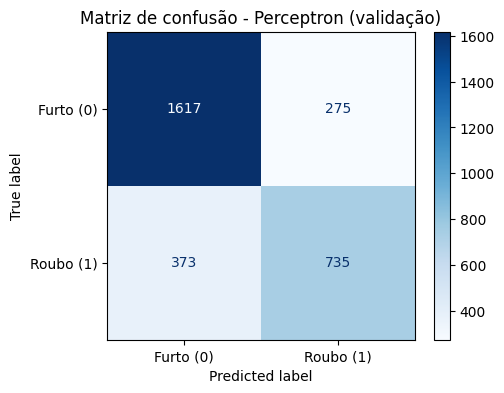

In [13]:
def metricas(y_true, y_pred):
    return {"Acurácia": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred, zero_division=0),
            "F1-Score": f1_score(y_true, y_pred, zero_division=0)}

# Avaliar na VALIDAÇÃO
pred_man_val = ((X_val_scaled @ w_man + b_man) >= 0).astype(int)
pred_perc_val = perc.predict(X_val_scaled)
print("--- Perceptron na VALIDAÇÃO ---")
display(pd.DataFrame({"Manual": metricas(y_val, pred_man_val),
                      "Scikit-learn": metricas(y_val, pred_perc_val)}).T.round(4))

# Matriz de confusão
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_val, pred_perc_val),
                       display_labels=['Furto (0)', 'Roubo (1)']).plot(cmap='Blues', ax=ax, values_format='d')
plt.title('Matriz de confusão - Perceptron (validação)'); plt.grid(False); plt.show()

Célula 13: MLPs, treino das 3 arquiteturas e comparativo na validação


In [14]:
tf.random.set_seed(42)
n_in = X_tr_scaled.shape[1]
print("Entradas da rede:", n_in)

# Peso das classes (desbalanceamento)
cw = compute_class_weight('balanced', classes=np.array([0, 1]), y=y_tr)
class_weight = {0: cw[0], 1: cw[1]}
print("class_weight:", class_weight)

# Construir e compilar
def build_mlp(hidden, activation='relu', lr=1e-3, dropout=0.0, l2=0.0, name='mlp'):
    m = tf.keras.Sequential(name=name)
    m.add(layers.Input(shape=(n_in,)))
    for u in hidden:
        m.add(layers.Dense(u, activation=activation,
                           kernel_regularizer=regularizers.l2(l2) if l2 > 0 else None))
        if dropout > 0:
            m.add(layers.Dropout(dropout))
    m.add(layers.Dense(1, activation='sigmoid'))          # saída binária: P(roubo)
    m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
              loss='binary_crossentropy', metrics=['accuracy'])
    return m

arquiteturas = {
    "A_Simples":       dict(hidden=[16],          activation='relu', lr=1e-3, dropout=0.0, l2=0.0),
    "B_Intermediaria": dict(hidden=[32, 16],      activation='relu', lr=1e-3, dropout=0.0, l2=0.0),
    "C_Regularizada":  dict(hidden=[128, 64, 32], activation='relu', lr=5e-4, dropout=0.3, l2=1e-4),
}

# Treinar com validação e avaliar
modelos, historicos, linhas = {}, {}, []
for nome, cfg in arquiteturas.items():
    print(f"\n===== Treinando {nome} =====")
    m = build_mlp(name=nome, **cfg)
    es = callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)
    h = m.fit(X_tr_scaled, y_tr,
              validation_data=(X_val_scaled, y_val),
              epochs=60, batch_size=64,
              class_weight=class_weight, callbacks=[es], verbose=0)
    modelos[nome], historicos[nome] = m, h

    p_val = m.predict(X_val_scaled, verbose=0).ravel()
    r = metricas(y_val, (p_val >= 0.5).astype(int))
    r.update({"Parâmetros": m.count_params(), "Épocas": len(h.history['loss']),
              "Val loss": min(h.history['val_loss'])})
    linhas.append(pd.Series(r, name=nome))

# Perceptron como baseline linear
linhas.insert(0, pd.Series({**metricas(y_val, pred_perc_val), "Parâmetros": X_tr_scaled.shape[1] + 1,
                            "Épocas": np.nan, "Val loss": np.nan}, name="Perceptron (baseline)"))

tabela = pd.DataFrame(linhas).round(4)
print("\n--- COMPARATIVO NA VALIDAÇÃO ---")
display(tabela)

# Seleção SOMENTE pela validação (entre as MLPs)
melhor = tabela.loc[list(arquiteturas.keys()), "F1-Score"].idxmax()
modelo_final = modelos[melhor]
print(f"\n✅ Modelo selecionado (maior F1 na validação): {melhor}")

Entradas da rede: 69
class_weight: {0: np.float64(0.792662212659948), 1: np.float64(1.3542271232346683)}

===== Treinando A_Simples =====

===== Treinando B_Intermediaria =====

===== Treinando C_Regularizada =====

--- COMPARATIVO NA VALIDAÇÃO ---


,Acurácia,Precision,Recall,F1-Score,Parâmetros,Épocas,Val loss
Perceptron (baseline),0.7840,0.7277,0.6634,0.6941,70.0,NaN,NaN
A_Simples,0.8237,0.7232,0.8466,0.7800,1137.0,60.0,0.4123
B_Intermediaria,0.8213,0.7177,0.8511,0.7787,2785.0,23.0,0.4172
C_Regularizada,0.8223,0.7262,0.8330,0.7760,19329.0,35.0,0.4229



✅ Modelo selecionado (maior F1 na validação): A_Simples


Célula 14: curvas e diagnóstico de overfitting


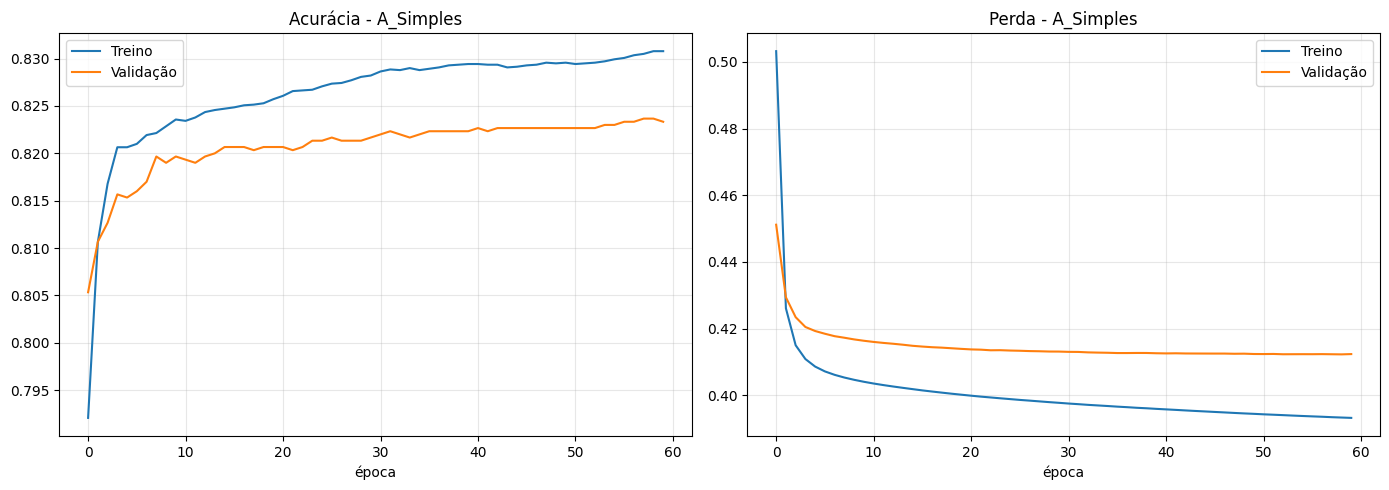

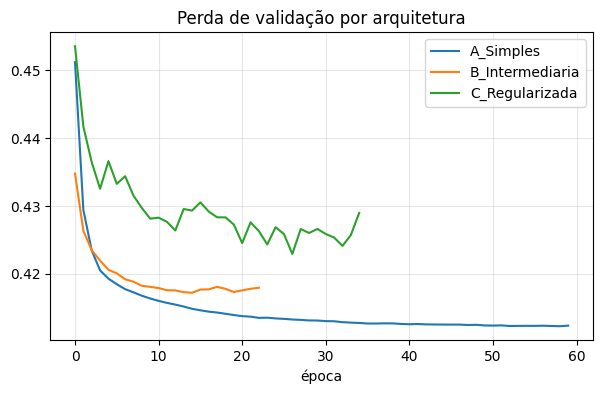

--- Diagnóstico ---
A_Simples: acc treino-val = +0.007 | loss val-treino = +0.019 | acc val = 0.823
B_Intermediaria: acc treino-val = +0.008 | loss val-treino = +0.027 | acc val = 0.824
C_Regularizada: acc treino-val = +0.010 | loss val-treino = +0.020 | acc val = 0.821
Regra prática: gap grande (treino bem melhor que validação) = overfitting; ambas as acurácias baixas = underfitting.


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
h = historicos[melhor].history
ax[0].plot(h['accuracy'], label='Treino'); ax[0].plot(h['val_accuracy'], label='Validação')
ax[0].set_title(f'Acurácia - {melhor}'); ax[0].set_xlabel('época'); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(h['loss'], label='Treino'); ax[1].plot(h['val_loss'], label='Validação')
ax[1].set_title(f'Perda - {melhor}'); ax[1].set_xlabel('época'); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

plt.figure(figsize=(7, 4))
for n, hh in historicos.items():
    plt.plot(hh.history['val_loss'], label=n)
plt.title('Perda de validação por arquitetura'); plt.xlabel('época'); plt.legend(); plt.grid(alpha=0.3); plt.show()

print("--- Diagnóstico ---")
for nome, hh in historicos.items():
    d = hh.history
    gap_acc = d['accuracy'][-1] - d['val_accuracy'][-1]
    gap_loss = d['val_loss'][-1] - d['loss'][-1]
    print(f"{nome}: acc treino-val = {gap_acc:+.3f} | loss val-treino = {gap_loss:+.3f} | "
          f"acc val = {d['val_accuracy'][-1]:.3f}")
print("Regra prática: gap grande (treino bem melhor que validação) = overfitting; "
      "ambas as acurácias baixas = underfitting.")

Célula 15: relatório e matriz de confusão do modelo escolhido (validação)


Relatório (validação):
              precision    recall  f1-score   support

       Furto       0.90      0.81      0.85      1892
       Roubo       0.72      0.85      0.78      1108

    accuracy                           0.82      3000
   macro avg       0.81      0.83      0.82      3000
weighted avg       0.83      0.82      0.83      3000

Matriz de confusão [[TN, FP], [FN, TP]]:
 [[1533  359]
 [ 170  938]]


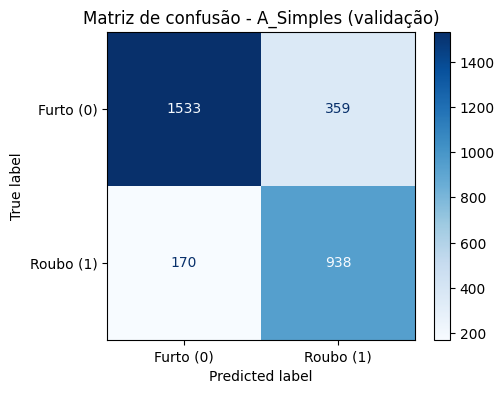

In [16]:
p_val = modelo_final.predict(X_val_scaled, verbose=0).ravel()
y_val_pred = (p_val >= 0.5).astype(int)

print("Relatório (validação):")
print(classification_report(y_val, y_val_pred, target_names=['Furto', 'Roubo'], zero_division=0))
print("Matriz de confusão [[TN, FP], [FN, TP]]:\n", confusion_matrix(y_val, y_val_pred))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_val, y_val_pred),
                       display_labels=['Furto (0)', 'Roubo (1)']).plot(cmap='Blues', ax=ax, values_format='d')
plt.title(f'Matriz de confusão - {melhor} (validação)'); plt.grid(False); plt.show()

Célula 16: avaliação final no TESTE e salvar o modelo


--- A_Simples no TESTE (avaliação final) ---
{'Acurácia': 0.813, 'Precision': 0.7056, 'Recall': 0.8464, 'F1-Score': 0.7696}
              precision    recall  f1-score   support

       Furto       0.90      0.79      0.84      1893
       Roubo       0.71      0.85      0.77      1107

    accuracy                           0.81      3000
   macro avg       0.80      0.82      0.81      3000
weighted avg       0.83      0.81      0.82      3000

[[1502  391]
 [ 170  937]]


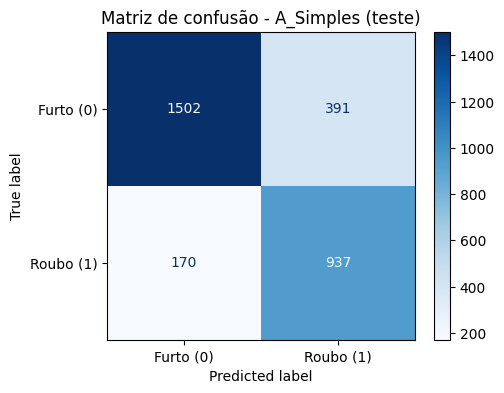

💾 Modelo salvo: mlp_roubo_furto.keras


In [17]:
# Rode com True UMA ÚNICA VEZ, quando a arquitetura estiver definitiva
AVALIAR_TESTE = True

if AVALIAR_TESTE:
    p_te = modelo_final.predict(X_te_scaled, verbose=0).ravel()
    y_te_pred = (p_te >= 0.5).astype(int)
    print(f"--- {melhor} no TESTE (avaliação final) ---")
    print({k: round(v, 4) for k, v in metricas(y_te, y_te_pred).items()})
    print(classification_report(y_te, y_te_pred, target_names=['Furto', 'Roubo'], zero_division=0))
    print(confusion_matrix(y_te, y_te_pred))

    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay(confusion_matrix(y_te, y_te_pred),
                           display_labels=['Furto (0)', 'Roubo (1)']).plot(cmap='Blues', ax=ax, values_format='d')
    plt.title(f'Matriz de confusão - {melhor} (teste)'); plt.grid(False); plt.show()

    modelo_final.save('mlp_roubo_furto.keras')
    print("💾 Modelo salvo: mlp_roubo_furto.keras")
else:
    print("⏸️ Teste reservado. Mude AVALIAR_TESTE = True só na avaliação final.")